##### Copyright 2022 The TensorFlow Compression Authors.

In [1]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Learned data compression

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://www.tensorflow.org/tutorials/generative/data_compression">
    <img src="https://www.tensorflow.org/images/tf_logo_32px.png" />
    View on TensorFlow.org</a>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/generative/data_compression.ipynb">
    <img src="https://www.tensorflow.org/images/colab_logo_32px.png" />
    Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/docs/blob/master/site/en/tutorials/generative/data_compression.ipynb">
    <img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />
    View source on GitHub</a>
  </td>
  <td>
    <a href="https://storage.googleapis.com/tensorflow_docs/docs/site/en/tutorials/generative/data_compression.ipynb"><img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
</table>

## Overview

This notebook shows how to do lossy data compression using neural networks and [TensorFlow Compression](https://github.com/tensorflow/compression).

Lossy compression involves making a trade-off between **rate**, the expected number of bits needed to encode a sample, and **distortion**, the expected error in the reconstruction of the sample.

The examples below use an autoencoder-like model to compress images from the MNIST dataset. The method is based on the paper [End-to-end Optimized Image Compression](https://arxiv.org/abs/1611.01704).

More background on learned data compression can be found in [this paper](https://arxiv.org/abs/2007.03034) targeted at people familiar with classical data compression, or [this survey](https://arxiv.org/abs/2202.06533) targeted at a machine learning audience.


## Setup

Install Tensorflow Compression via `pip`.

In [2]:
# %%bash
# # Installs the latest version of TFC compatible with the installed TF version.

# read MAJOR MINOR <<< "$(pip show tensorflow | perl -p -0777 -e 's/.*Version: (\d+)\.(\d+).*/\1 \2/sg')"
# pip install "tensorflow-compression<$MAJOR.$(($MINOR+1))"


Import library dependencies.

In [1]:
import tensorrt
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_compression as tfc
import tensorflow_datasets as tfds

2023-12-22 00:22:05.315313: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
!printenv | grep XLA

XLA_FLAGS=--xla_gpu_cuda_data_dir=/usr/lib/cuda/


Correct error for GPU memory usage and check if the GPU is available

In [3]:
physical_devices = tf.config.list_physical_devices('GPU')
print(physical_devices)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2023-12-22 00:22:18.869216: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2023-12-22 00:22:19.018108: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2023-12-22 00:22:19.018343: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

In [4]:
# Set GPU memory limit
tf.config.experimental.set_memory_growth(physical_devices[0], True)

## Define the trainer model.

Because the model resembles an autoencoder, and we need to perform a different set of functions during training and inference, the setup is a little different from, say, a classifier.

The training model consists of three parts:
- the **analysis** (or encoder) transform, converting from the image into a latent space,
- the **synthesis** (or decoder) transform, converting from the latent space back into image space, and
- a **prior** and entropy model, modeling the marginal probabilities of the latents.

First, define the transforms:

In [5]:
# the encoder(analysis transform) is a NN with 4 layers: two 2D CONV layers and 2 FC layers! 
# The 1st convolutional layer has: 
# - 20 filters (the dimensionality of the output space (i.e. the number of output filters in the convolution)
# - kernel size of 5 (height and width of the 2D convolution window)
# - 2 strides (specifying the strides of the convolution along the height and width, the step size of the convolution window!)
# - padding:"same" results in padding with zeros evenly to the left/right or up/down of the input
# - If use_bias is True, a bias vector is created and added to the outputs

# The 2nd convolutional layer is very similar to the 1st but the spectral dimension increases (output features are smaller but are more)

# We end up with 50 features that are vectorized: small images are converted to vectors (flattened)

# Now, a 2 layers fully connected network is used to find the optimal regression function!

# Every image is converted in a vector (code) in the latent space! The dimension of the vector is related to the rate/distortion tradeoff (I guess...)

def make_analysis_transform(latent_dims):
  """Creates the analysis (encoder) transform."""
  return tf.keras.Sequential([
            
            # 1st conv layer
            tf.keras.layers.Conv2D(
                20, 
                5, 
                use_bias = True, 
                strides=2, 
                padding="same",
                activation="leaky_relu",
                name="conv_1"),
            
            # 2nd conv layer
            tf.keras.layers.Conv2D(
                50, 
                5,
                use_bias = True,
                strides=2, 
                padding="same",
                activation="leaky_relu",
                name="conv_2"),
            
            tf.keras.layers.Flatten(),
            
            tf.keras.layers.Dense(
                500, 
                use_bias = True,
                activation="leaky_relu", 
                name="fc_1"),
            
            tf.keras.layers.Dense(
                latent_dims,
                use_bias = True,
                activation = None,
                name="fc_2"),
            ], 
            name="analysis_transform")


In [6]:
# The decoder (synthesis transform) is a NN that converst codes (vectors in the latent space) into images! 
# This is done using a 2 layers fully connected network to learn the optimal feature to retrieve the original images, 
# and that applying a 2 layers 2D convolutional netowrk to retrieve the images.

def make_synthesis_transform():
  """Creates the synthesis (decoder) transform."""
  return tf.keras.Sequential([
      
            tf.keras.layers.Dense(
                500, 
                use_bias=True,
                activation="leaky_relu",
                name="fc_1"),
            
            tf.keras.layers.Dense(
                2450,
                use_bias=True,
                activation="leaky_relu",
                name="fc_2"),
            
            tf.keras.layers.Reshape((7, 7, 50)),
            
            tf.keras.layers.Conv2DTranspose(
                20, 
                5, 
                use_bias=True, 
                strides=2, 
                padding="same",
                activation="leaky_relu", 
                name="conv_1"),
            
            tf.keras.layers.Conv2DTranspose(
                1,
                5,
                use_bias=True,
                strides=2, 
                padding="same",
                activation="leaky_relu", 
                name="conv_2"),
        
            ], name="synthesis_transform")


The trainer holds an instance of both transforms, as well as the parameters of the prior.

Its `call` method is set up to compute:
- **rate**, an estimate of the number of bits needed to represent the batch of digits, and
- **distortion**, the mean absolute difference between the pixels of the original digits and their reconstructions.


In [7]:
# Trainter object, we use this class for the training + computation of rate and distortion
# There are 3 methods:
# - constructor: creates analysis, synthesis and creates the scales according to the number of latent dimensions
# - prior: builds the prior
# - call: given an x, computes the rate and the distortion

# Trainer object
class MNISTCompressionTrainer(tf.keras.Model):
  """Model that trains a compressor/decompressor for MNIST."""

  # Constructor
  def __init__(self, latent_dims):
    super().__init__()
    
    # Set analysis and synthesis NNs (build the NNs structures)
    self.analysis_transform = make_analysis_transform(latent_dims)
    self.synthesis_transform = make_synthesis_transform()
    
    # This should be the standard deviations of the latent dimensions of the latent vectors. The 10 std define the multimodal distribution of the latent vectors
    # Create the prior_log_scales variable (array of 10 zeros that will change with learning, I guess...)
    # the fact that they are defined logarithmic is just a convention
    self.prior_log_scales = tf.Variable(tf.zeros((latent_dims,))) 
    # The Variable() constructor requires an initial value for the variable, which can be a Tensor of any type and shape. 
    # This initial value defines the type and shape of the variable. After construction, the type and shape of the variable are fixed. 
    # The value can be changed using one of the assign methods.


  # The prior is initialized, nothing special: it uses the scales defined above (10 scales in this case)
  # property decorator: this is Python's way of creating getters, setters, and deleters (or mutator methods) for a property in a class.
  @property
  def prior(self):
    # NoisyLogistic: logistic distribution with additive i.i.d. uniform noise.
    return tfc.NoisyLogistic(loc=0., scale=tf.exp(self.prior_log_scales))


  # Call method sets up and compute the rate and the distortion
  def call(self, x, training):
    """Computes rate and distortion losses for a single image x."""
    # --training-- is a parameter that controls how the rate is computed (during training adding additive noise, during validation/testing with quantization)
    
    # Ensure inputs are floats in the range (0, 1).
    x = tf.cast(x, self.compute_dtype) / 255.
    # Add a batch dimension (28x28 are the spatial dimensions of the input image)
    x = tf.reshape(x, (-1, 28, 28, 1))

    # Compute latent space representation y, perturb it (additive noise during trainign or quantization during validation/testing),
    # then compute the reconstructed pixel-level representation x_hat.
    y = self.analysis_transform(x)
    entropy_model = tfc.ContinuousBatchedEntropyModel(self.prior, coding_rank=1, compression=False)
    y_tilde, rate = entropy_model(y, training=training)  
    x_tilde = self.synthesis_transform(y_tilde)

    # Average number of bits per MNIST digit.
    rate = tf.reduce_mean(rate) # reduce_mean computes the mean across the dimensions of the tensor, here (10,) 

    # Mean absolute difference across pixels.
    distortion = tf.reduce_mean(abs(x - x_tilde)) # distortion computed as MAE (not MSE)

    # returns all the rate/distortion pairs
    return dict(rate=rate, distortion=distortion)


### Loading datasets

In [8]:
# Loads the data to use (MNIST images)

mnist_training_dataset, mnist_validation_dataset = tfds.load(
    "mnist",
    split=["train", "test"],
    shuffle_files=True,
    as_supervised=True,
    with_info=False,
)

2023-12-22 00:22:24.715333: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2023-12-22 00:22:24.715595: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2023-12-22 00:22:24.715761: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

In [9]:
# Loads the data to use (low resolution cat images)

lcat_training_dataset, lcat_validation_dataset = tfds.load(
    "cifar10",
    split=["train", "test"],
    shuffle_files=True,
    as_supervised=True,
    with_info=False,
)

In [10]:
# Keeps only cat images
# lcat_training_dataset = lcat_training_dataset.filter(lambda X, y: y == 3)
# lcat_validation_dataset = lcat_validation_dataset.filter(lambda label: label == 3)


In [11]:
# lcat_training_dataset.cardinality().numpy() # [-2: undeterminated cardinality]

# Try to print the first elements to check the value and class
# # Assuming `my_dataset` is your dataset
# my_dataset = lcat_training_dataset  # Replace ... with your actual dataset
#
# # Convert to a numpy iterator
# dataset_iterator = iter(my_dataset.as_numpy_iterator())
#
# # Iterate through the dataset and print the elements
# i = 0
# for element in dataset_iterator:
#     i=i+1 
#     print(element[1]) # element[1] is the label
#     if i == 10:
#         break

In [12]:
# high resolution cat dataset 
import numpy as np
import h5py    
    
def load_dataset():
    train_dataset = h5py.File('datasets/train_catvnoncat.h5', "r")
    train_set_x_orig = np.array(train_dataset["train_set_x"][:]) # your train set features
    train_set_y_orig = np.array(train_dataset["train_set_y"][:]) # your train set labels

    test_dataset = h5py.File('datasets/test_catvnoncat.h5', "r")
    test_set_x_orig = np.array(test_dataset["test_set_x"][:]) # your test set features
    test_set_y_orig = np.array(test_dataset["test_set_y"][:]) # your test set labels

    classes = np.array(test_dataset["list_classes"][:]) # the list of classes
    
    train_set_y_orig = train_set_y_orig.reshape((1, train_set_y_orig.shape[0]))
    test_set_y_orig = test_set_y_orig.reshape((1, test_set_y_orig.shape[0]))
    
    return train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig, classes

def extract_class_images(class_index, train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig):
    # Get the indices of examples that belong to the specified class
    train_class_indices = np.where(train_set_y_orig == class_index)[1]
    test_class_indices = np.where(test_set_y_orig == class_index)[1]

    # Extract images and labels of the specified class
    train_class_images = train_set_x_orig[train_class_indices]
    train_class_labels = train_set_y_orig[:, train_class_indices]

    test_class_images = test_set_x_orig[test_class_indices]
    test_class_labels = test_set_y_orig[:, test_class_indices]

    return train_class_images, train_class_labels, test_class_images, test_class_labels

# not_cat: 0
# cat: 1
class_index=1
train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig, classes = load_dataset()
hcat_train_class_images, hcat_train_class_labels, hcat_test_class_images, hcat_test_class_labels = extract_class_images(class_index, train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig)
# plt.imshow(hcat_train_class_images[42])


In [13]:
# Datasets info
print("Number of training examples of MNIST:", mnist_training_dataset.cardinality().numpy())
print("Number of testing examples of MNIST:", mnist_validation_dataset.cardinality().numpy())

print("Number of training examples of High Res CATS:", len(hcat_train_class_images))
print("Number of testing examples of High Res CATS:", len(hcat_test_class_images))

Number of training examples of MNIST: 60000
Number of testing examples of MNIST: 10000
Number of training examples of High Res CATS: 72
Number of testing examples of High Res CATS: 33


### Example of analysis and synthesis application (before training). Computation of the rate and distortion of an image as a didactic example

Let's walk through this step by step, using one image from the training set. Load the MNIST dataset for training and validation:

Extract one image $x$:

In [14]:
(x, y), = mnist_validation_dataset.take(1)

# plt.imshow(tf.squeeze(x))
# print(f"Data type: {x.dtype}")
# print(f"Shape: {x.shape}")

2023-12-22 00:22:29.320583: W tensorflow/core/kernels/data/cache_dataset_ops.cc:854] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


2023-12-22 00:22:29.786794: W tensorflow/core/kernels/data/cache_dataset_ops.cc:854] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


Data type: <dtype: 'uint8'>
Shape: (28, 28, 1)


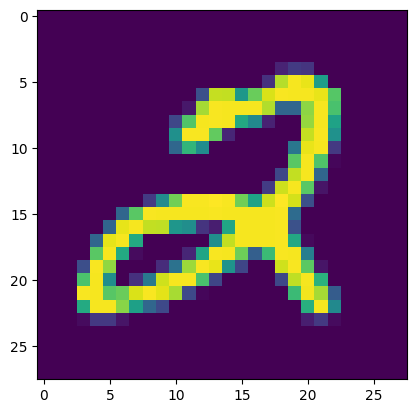

In [15]:
# Take one image from the dataset and observe it
(x, _), = mnist_validation_dataset.take(1)

plt.imshow(tf.squeeze(x))
print(f"Data type: {x.dtype}")
print(f"Shape: {x.shape}")


Data type: uint8
Shape: (64, 64, 3)


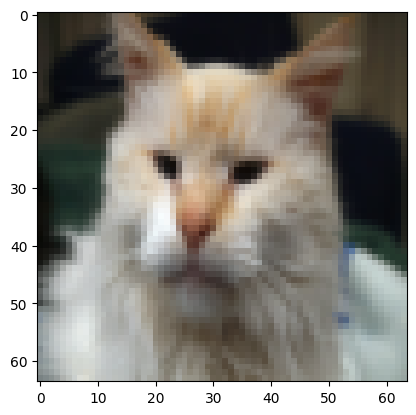

In [16]:
cat = hcat_train_class_images[8] #2, 4, 8

plt.imshow(tf.squeeze(cat))
print(f"Data type: {cat.dtype}")
print(f"Shape: {cat.shape}")

Data type: uint8
Shape: (28, 28)


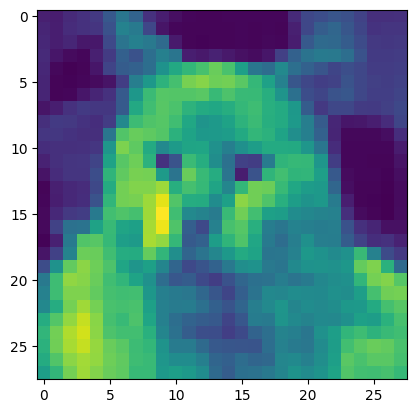

In [17]:
import cv2

cat = cv2.resize(cat, (28, 28), interpolation=cv2.INTER_AREA)
cat = cv2.cvtColor(cat, cv2.COLOR_BGR2GRAY)

plt.imshow(cat)
print(f"Data type: {cat.dtype}")
print(f"Shape: {cat.shape}")

To get the latent representation $y$, we need to cast it to `float32`, add a batch dimension, and pass it through the analysis transform.

In [18]:
# Cast the image to float32
x = tf.cast(x, tf.float32) / 255.

# Add a batch dimension (training, validation, other sets in which the data can be divided)
x = tf.reshape(x, (-1, 28, 28, 1))

x.shape

# Given x, get the 10 dimensional vector y representing x
y = make_analysis_transform(10)(x)

# print 
print("y, latent represention of x:", y)

2023-12-22 00:22:38.333296: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:432] Loaded cuDNN version 8904


y, latent represention of x: tf.Tensor(
[[ 0.08637248  0.03365373  0.00397443 -0.0435495  -0.02416941 -0.04811544
  -0.02732229  0.05334272 -0.04207277  0.0896211 ]], shape=(1, 10), dtype=float32)


The latents will be quantized at test time. To model this in a differentiable way during training, we add uniform noise in the interval $(-.5, .5)$ and call the result $\tilde y$. This is the same terminology as used in the paper [End-to-end Optimized Image Compression](https://arxiv.org/abs/1611.01704).

In [19]:
# As written in the paper, quantization is applied in the latent space! 
# This is ok in testing, but during training it is necessary to have differentiable data, thus uniform noise is added to the latent representation to simulate quantization
# The interval of uniform noise is (-0.5,0.5) because the quantization bin has length 1
y_tilde = y + tf.random.uniform(y.shape, -.5, .5)

# This is just an example, in the real training we do this through the use of "tfc.entropy_model"

print("y_tilde:", y_tilde)

y_tilde: tf.Tensor(
[[ 0.2889458  -0.25522614 -0.22509837 -0.21284933  0.3450593   0.34182662
  -0.40919065 -0.13772677 -0.36371362 -0.3695589 ]], shape=(1, 10), dtype=float32)


The "prior" is a probability density that we train to model the marginal distribution of the noisy latents. For example, it could be a set of independent [logistic distributions](https://en.wikipedia.org/wiki/Logistic_distribution) with different scales for each latent dimension. `tfc.NoisyLogistic` accounts for the fact that the latents have additive noise. As the scale approaches zero, a logistic distribution approaches a dirac delta (spike), but the added noise causes the "noisy" distribution to approach the uniform distribution instead.

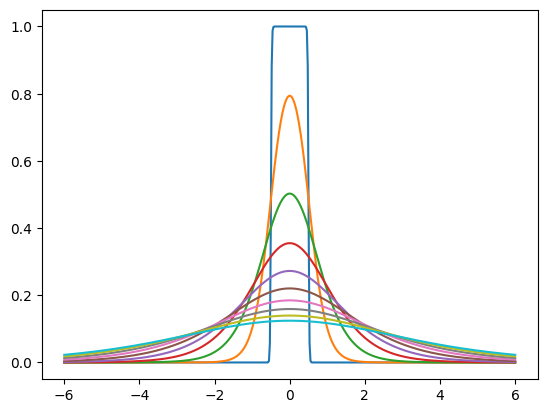

In [20]:
# THIS IS JUST AN EXAMPLE TO SHOW THE EFFECT OF THE DIFFERENT SCALES ON THE PRIOR, 
# in reality the prior is initialized with scales that are all 1s, meaning they are all normal gaussians at the beginning (identically distributed).

# prior is a distribution, here we define the dimension of prior through the number of scales (here 10, defined with linspace)
# loc is the pdf center ()
prior = tfc.NoisyLogistic(loc=0., scale=tf.linspace(.01, 2., 10))

# show an example of prior with different scales (stds) just for the sake of understanding
_ = tf.linspace(-6., 6., 501)[:, None]
plt.plot(_, prior.prob(_));


During training, `tfc.ContinuousBatchedEntropyModel` adds uniform noise, and uses the noise and the prior to compute a (differentiable) upper bound on the rate (the average number of bits necessary to encode the latent representation). That bound can be minimized as a loss.

In [21]:
# STILL AN EXAMPLE
# here we actually compute the y_tilde as we do in the trainer, hence using "entropy_model"

entropy_model = tfc.ContinuousBatchedEntropyModel(
    prior, coding_rank=1, compression=False)

y_tilde, rate = entropy_model(y, training=True)

# y is the latent vector output of the analysis transform
# y_tilde is y + uniform noise (because training=true)
# the rate is computed with the prior and the noise (this would be the distribution after the "quantization")

print("rate:", rate)
print("y_tilde:", y_tilde)

rate: tf.Tensor([18.346897], shape=(1,), dtype=float32)
y_tilde: tf.Tensor(
[[ 0.25360656  0.03892457 -0.48819184 -0.4825444   0.0694311   0.16643423
  -0.16703987  0.27468768  0.3158971   0.5252877 ]], shape=(1, 10), dtype=float32)


Lastly, the noisy latents are passed back through the synthesis transform to produce an image reconstruction $\tilde x$. Distortion is the error between original image and reconstruction. Obviously, with the transforms untrained, the reconstruction is not very useful.

distortion: tf.Tensor(0.17088675, shape=(), dtype=float32)
Data type: <dtype: 'uint8'>
Shape: (28, 28, 1)


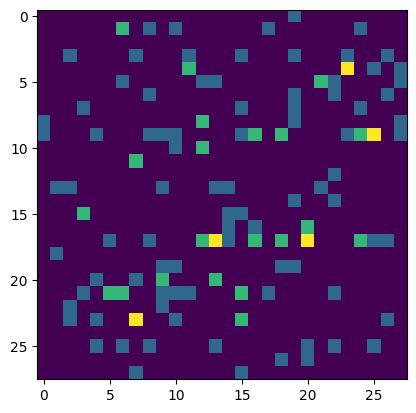

In [22]:
# reconstructed image
x_tilde = make_synthesis_transform()(y_tilde)

# distortion: Mean absolute difference across pixels.
distortion = tf.reduce_mean(abs(x - x_tilde))
print("distortion:", distortion)

# cast reconstructed x in [0, 255] instead of [0,1], casted to uint8 because it's an image (28x28)
x_tilde = tf.saturate_cast(x_tilde[0] * 255, tf.uint8)

plt.imshow(tf.squeeze(x_tilde)) #squeeze just removes the dimensions of size one (like the batch in this case)
print(f"Data type: {x_tilde.dtype}")
print(f"Shape: {x_tilde.shape}")

# this result is an image reconstructed with the synthesis transform. y_tilde here is basically a random vector since we added uniform noise before.
# The image looks bad because the synthesis transform is untrained, with weights that are randomly initialized.

For every batch of digits, calling the `MNISTCompressionTrainer` produces the rate and distortion as an average over that batch:


In [23]:
# Here we compute the rate and distortion for a batch of 32 digits using the trainer defined above

# taking a batch of images from validation set
(example_batch, _), = mnist_validation_dataset.batch(32).take(1)

# Instance of the trainer with latent_dimensions=10
trainer = MNISTCompressionTrainer(10)

# example_output is a dict {rate, dist} built in the call() method of the Trainer
example_output = trainer(example_batch)

print("rate: ", example_output["rate"])
print("distortion: ", example_output["distortion"])


2023-12-22 00:22:49.640071: W tensorflow/core/kernels/data/cache_dataset_ops.cc:854] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


rate:  tf.Tensor(20.296253, shape=(), dtype=float32)
distortion:  tf.Tensor(0.14659302, shape=(), dtype=float32)


In the next section, we set up the model to do gradient descent on these two losses.

## Train the model

We compile the trainer in a way that it optimizes the rate–distortion Lagrangian, that is, a sum of rate and distortion, where one of the terms is weighted by Lagrange parameter $\lambda$.

This loss function affects the different parts of the model differently:
- The analysis transform is trained to produce a latent representation that achieves the desired trade-off between rate and distortion.
- The synthesis transform is trained to minimize distortion, given the latent representation.
- The parameters of the prior are trained to minimize the rate given the latent representation. This is identical to fitting the prior to the marginal distribution of latents in a maximum likelihood sense.

In [24]:
# hyperparameters
LATENT_DIM = 10
LEARNING_RATE = 1e-3

# UNSUPERVISED LEARNING! 
def pass_through_loss(_, x):
  # Since rate and distortion are unsupervised, the loss doesn't need a target.
  return x


# TRAINER INSTANTIATION AND INITIALIZATION
# function that initializes the trainer with:
# - a given latent dimension
# - a given lamba(rate/distorition trade off)
def make_mnist_compression_trainer(lmbda, latent_dims=LATENT_DIM):
  # create trainer object (constructor is executed!)
  trainer = MNISTCompressionTrainer(latent_dims)
  # setting training parameters
  trainer.compile(
    # set training algorithm (Adam with the learning rate)
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    # define loss function for training (just pass through rate and distortion as losses/metrics)
    loss = dict(rate=pass_through_loss, distortion=pass_through_loss),
    metrics = dict(rate=pass_through_loss, distortion=pass_through_loss),
    loss_weights = dict(rate=1., distortion=lmbda),
  )
  return trainer


Next, train the model. The human annotations are not necessary here, since we just want to compress the images, so we drop them using a `map` and instead add "dummy" targets for rate and distortion.

In [28]:
# Define "dummy" labels
def add_rd_targets(image, label):
  # Training is unsupervised, so labels aren't necessary here. However, we
  # need to add "dummy" targets for rate and distortion.
  return image, dict(rate=0., distortion=0.)


# TRAINING (given a lambda)
def train_mnist_model(lmbda):
  
  # create trainer, define training algorithm and loss function to optimize
  trainer = make_mnist_compression_trainer(lmbda)

  # Perform training
  trainer.fit(
      # take training batch
      mnist_training_dataset.map(add_rd_targets).batch(128).prefetch(8),
      epochs=15,
      # take validation batch
      validation_data=mnist_validation_dataset.map(add_rd_targets).batch(128).cache(),
      validation_freq=1,
      verbose=1,
  )
  return trainer

In [ ]:
# Finally train the model with given lambda
lmbda=2000
trainer = train_mnist_model(lmbda)
# trainer.save(f"mnist_trainer_{lmbda}")

## Compress some MNIST images.

For compression and decompression at test time, we split the trained model in two parts:

- The encoder side consists of the analysis transform and the entropy model.
- The decoder side consists of the synthesis transform and the same entropy model.

At test time, the latents will not have additive noise, but they will be quantized and then losslessly compressed, so we give them new names. We call them and the image reconstruction $\hat x$ and $\hat y$, respectively (following [End-to-end Optimized Image Compression](https://arxiv.org/abs/1611.01704)).

In [35]:
# class of the COMPRESSION MODEL (trained model)
# methods:
# - constructor: uses the leart analysis (transform learnt to max the rate and min the dist) and entropy model (distribution of the latent learnt to max the rate)
# - call: given an image x it compresses it and encodes it + it computes the rate using entropy_model with training=False (quantization) 

class MNISTCompressor(tf.keras.Model):
  """Compresses MNIST images to strings."""

  # constructor
  def __init__(self, analysis_transform, entropy_model):
    super().__init__()
    # analysis here is optimal after training
    self.analysis_transform = analysis_transform
    # entropy model is optimal after training
    self.entropy_model = entropy_model

  def call(self, x):

    # Ensure inputs are floats in the range (0, 1).
    x = tf.cast(x, self.compute_dtype) / 255.
    
    # actual compression
    y = self.analysis_transform(x)

    # Also return the exact information content of each digit.
    _, bits = self.entropy_model(y, training=False)
    
    return self.entropy_model.compress(y), bits


In [36]:
# class of the DECOMPRESSION MODEL (trained model)
# methods:
# - constructor: uses the learnt synthesis (transform learnt to min the dist) and entropy model (distribution of the latent learnt to max the rate)
# - call: given a string it decodes it + decompresses it

class MNISTDecompressor(tf.keras.Model):
  """Decompresses MNIST images from strings."""

  def __init__(self, entropy_model, synthesis_transform):
    super().__init__()
    self.entropy_model = entropy_model
    self.synthesis_transform = synthesis_transform

  def call(self, string):
    # decode the vector in the latent space
    y_hat = self.entropy_model.decompress(string, ())
    # reconstruct the image from the vector
    x_hat = self.synthesis_transform(y_hat)
    
    # Scale and cast back to 8-bit integer.
    return tf.saturate_cast(tf.round(x_hat * 255.), tf.uint8)


When instantiated with `compression=True`, the entropy model converts the learned prior into tables for a range coding algorithm. When calling `compress()`, this algorithm is invoked to convert the latent space vector into bit sequences. The length of each binary string approximates the information content of the latent (the negative log likelihood of the latent under the prior).

The entropy model for compression and decompression must be the same instance, because the range coding tables need to be exactly identical on both sides. Otherwise, decoding errors can occur.

In [39]:
# lmbda = 2000
# trainer = tf.keras.models.load_model("mnist_trainer_2000")

def make_mnist_codec(trainer, **kwargs):
  # The entropy model must be created with `compression=True` and the same
  # instance must be shared between compressor and decompressor.
  entropy_model = tfc.ContinuousBatchedEntropyModel(
      trainer.prior, coding_rank=1, compression=True, **kwargs)
  compressor = MNISTCompressor(trainer.analysis_transform, entropy_model)
  decompressor = MNISTDecompressor(entropy_model, trainer.synthesis_transform)
  return compressor, decompressor

compressor, decompressor = make_mnist_codec(trainer)


Grab 16 images from the validation dataset. You can select a different subset by changing the argument to `skip`.

In [40]:
# MNIST
(mnist_originals, _), = mnist_validation_dataset.batch(16).skip(2).take(1)

mnist_originals.shape

TensorShape([16, 28, 28, 1])

In [41]:
import cv2

# HIGH RES CATS
cat_originals = hcat_train_class_images[:16]

cat_originals = [cv2.resize(x, (28, 28), interpolation=cv2.INTER_AREA) for x in cat_originals]
cat_originals = [cv2.cvtColor(x, cv2.COLOR_BGR2GRAY) for x in cat_originals]

cat_originals = tf.convert_to_tensor(cat_originals, dtype=tf.uint8)
cat_originals[:,:,:,None].shape

TensorShape([16, 28, 28, 1])

Compress them to strings, and keep track of each of their information content in bits.

In [42]:
mnist_strings, mnist_entropies = compressor(mnist_originals)

print(f"String representation of first digit in hexadecimal: 0x{mnist_strings[0].numpy().hex()}")
print(f"Number of bits actually needed to represent it: {mnist_entropies[0]:0.2f}")


String representation of first digit in hexadecimal: 0x509d93495f
Number of bits actually needed to represent it: 36.21


In [43]:
cat_strings, cat_entropies = compressor(cat_originals)

print(f"String representation of first digit in hexadecimal: 0x{cat_strings[0].numpy().hex()}")
print(f"Number of bits actually needed to represent it: {cat_entropies[0]:0.2f}")


String representation of first digit in hexadecimal: 0x24ac0702
Number of bits actually needed to represent it: 30.41


Decompress the images back from the strings.

In [44]:
mnist_reconstructions = decompressor(mnist_strings)
cat_reconstructions = decompressor(cat_strings)

Display each of the 16 original digits together with its compressed binary representation, and the reconstructed digit.

In [45]:
#@title

def display_digits(originals, strings, entropies, reconstructions):
  """Visualizes 16 digits together with their reconstructions."""
  fig, axes = plt.subplots(4, 4, sharex=True, sharey=True, figsize=(12.5, 5))
  axes = axes.ravel()
  for i in range(len(axes)):
    image = tf.concat([
        tf.squeeze(originals[i]),
        tf.zeros((28, 14), tf.uint8),
        tf.squeeze(reconstructions[i]),
    ], 1)
    axes[i].imshow(image)
    axes[i].text(
        .5, .5, f"→ 0x{strings[i].numpy().hex()} →\n{entropies[i]:0.2f} bits",
        ha="center", va="top", color="white", fontsize="small",
        transform=axes[i].transAxes)
    axes[i].axis("off")
  plt.subplots_adjust(wspace=0, hspace=0, left=0, right=1, bottom=0, top=1)


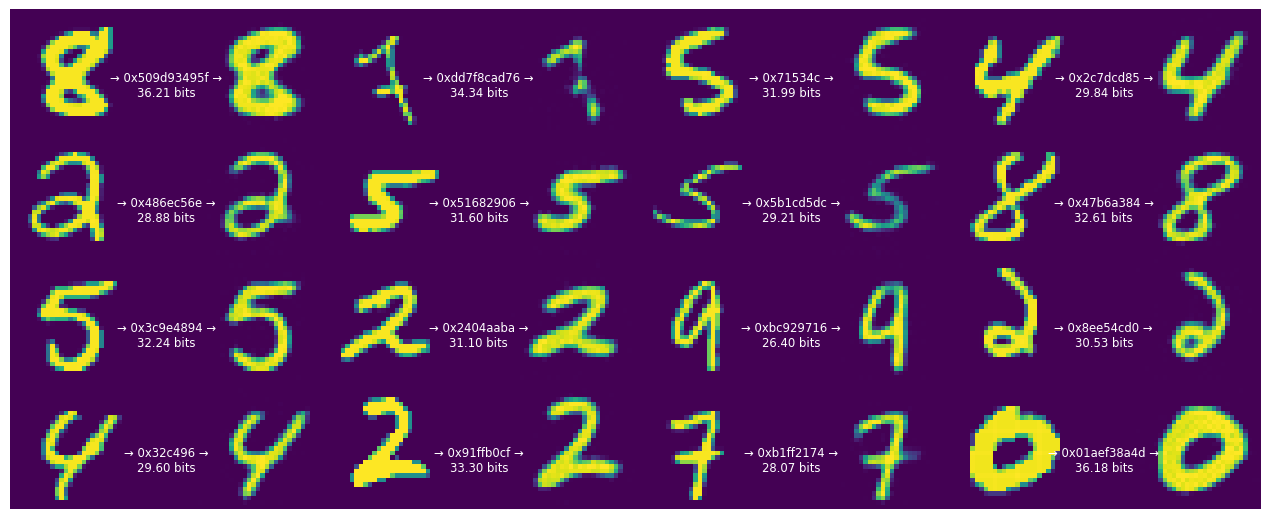

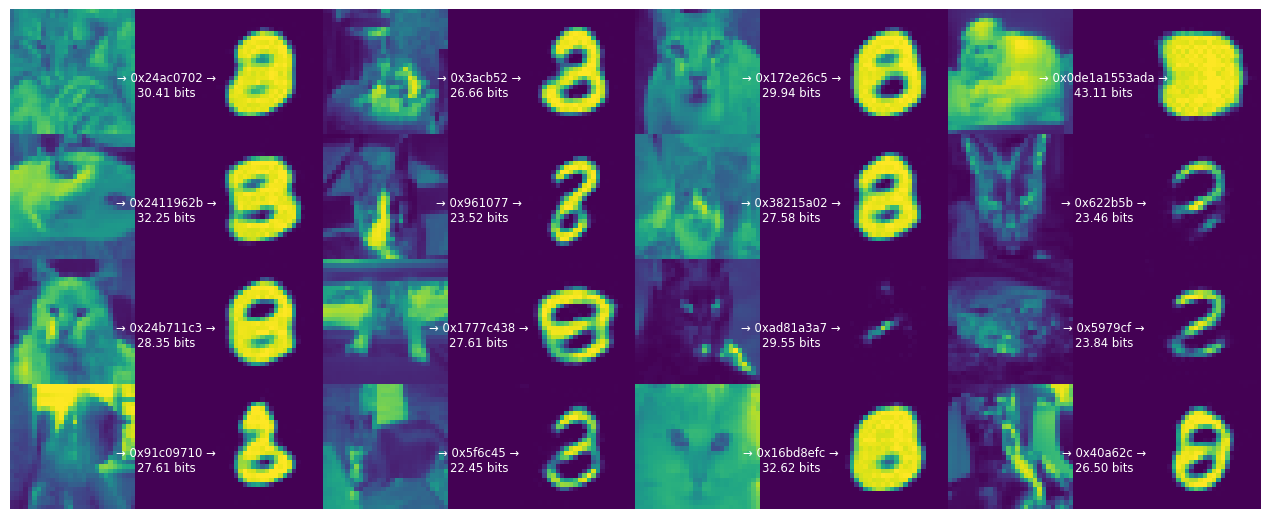

In [46]:
display_digits(mnist_originals, mnist_strings, mnist_entropies, mnist_reconstructions)
display_digits(cat_originals, cat_strings, cat_entropies, cat_reconstructions)


Note that the length of the encoded string differs from the information content of each digit.

This is because the range coding process works with discrete probabilities, and has a small amount of overhead. So, especially for short strings, the correspondence is only approximate. However, range coding is **asymptotically optimal**: in the limit, the expected bit count will approach the cross entropy (the expected information content), for which the rate term in the training model is an upper bound.

## The rate–distortion trade-off

Above, the model was trained for a specific trade-off (given by `lmbda=2000`) between the average number of bits used to represent each digit and the incurred error in the reconstruction.

What happens when we repeat the experiment with different values?

Let's start by reducing $\lambda$ to 500.

Epoch 1/15
466/469 [============================>.] - ETA: 0s - loss: 59.8371 - distortion_loss: 0.0773 - rate_loss: 21.1841 - distortion_pass_through_loss: 0.0773 - rate_pass_through_loss: 21.1841

469/469 [==============================] - 13s 19ms/step - loss: 59.7879 - distortion_loss: 0.0772 - rate_loss: 21.1785 - distortion_pass_through_loss: 0.0772 - rate_pass_through_loss: 21.1780 - val_loss: 52.2822 - val_distortion_loss: 0.0639 - val_rate_loss: 20.3430 - val_distortion_pass_through_loss: 0.0639 - val_rate_pass_through_loss: 20.3437
Epoch 2/15
469/469 [==============================] - 8s 18ms/step - loss: 50.7699 - distortion_loss: 0.0635 - rate_loss: 19.0425 - distortion_pass_through_loss: 0.0635 - rate_pass_through_loss: 19.0417 - val_loss: 49.1638 - val_distortion_loss: 0.0630 - val_rate_loss: 17.6697 - val_distortion_pass_through_loss: 0.0630 - val_rate_pass_through_loss: 17.6709
Epoch 3/15
469/469 [==============================] - 8s 18ms/step - loss: 48.5325 - distortion_loss: 0.0625 - rate_loss: 17.2801 - distortion_pass_through_loss: 0.0625 - rate_pass_through_loss: 17.2796 - val_loss: 47.5595 - val_distortion_loss: 0.0622 - val_rate_loss: 16.4809 - val_distorti

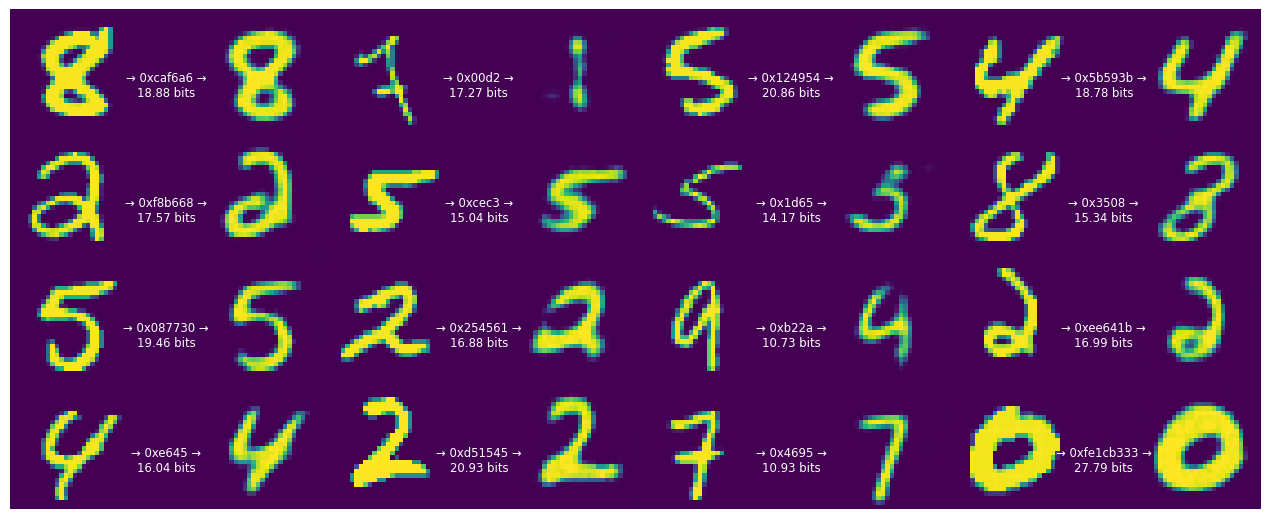

In [39]:
def train_and_visualize_model(lmbda):
  trainer = train_mnist_model(lmbda=lmbda)
  compressor, decompressor = make_mnist_codec(trainer)
  strings, entropies = compressor(mnist_originals)
  reconstructions = decompressor(strings)
  display_digits(mnist_originals, strings, entropies, reconstructions)

train_and_visualize_model(lmbda=500)


The bit rate of our code goes down, as does the fidelity of the digits. However, most of the digits remain recognizable.

Let's reduce $\lambda$ further.

Epoch 1/15
468/469 [============================>.] - ETA: 0s - loss: 44.2081 - distortion_loss: 0.0802 - rate_loss: 20.1566 - distortion_pass_through_loss: 0.0802 - rate_pass_through_loss: 20.1566

469/469 [==============================] - 12s 19ms/step - loss: 44.1972 - distortion_loss: 0.0801 - rate_loss: 20.1539 - distortion_pass_through_loss: 0.0801 - rate_pass_through_loss: 20.1530 - val_loss: 39.1090 - val_distortion_loss: 0.0684 - val_rate_loss: 18.5882 - val_distortion_pass_through_loss: 0.0684 - val_rate_pass_through_loss: 18.5894
Epoch 2/15
469/469 [==============================] - 8s 18ms/step - loss: 37.6470 - distortion_loss: 0.0688 - rate_loss: 17.0008 - distortion_pass_through_loss: 0.0688 - rate_pass_through_loss: 17.0000 - val_loss: 36.0035 - val_distortion_loss: 0.0685 - val_rate_loss: 15.4631 - val_distortion_pass_through_loss: 0.0685 - val_rate_pass_through_loss: 15.4623
Epoch 3/15
469/469 [==============================] - 8s 18ms/step - loss: 35.3943 - distortion_loss: 0.0699 - rate_loss: 14.4109 - distortion_pass_through_loss: 0.0699 - rate_pass_through_loss: 14.4103 - val_loss: 34.3874 - val_distortion_loss: 0.0706 - val_rate_loss: 13.2144 - val_distorti

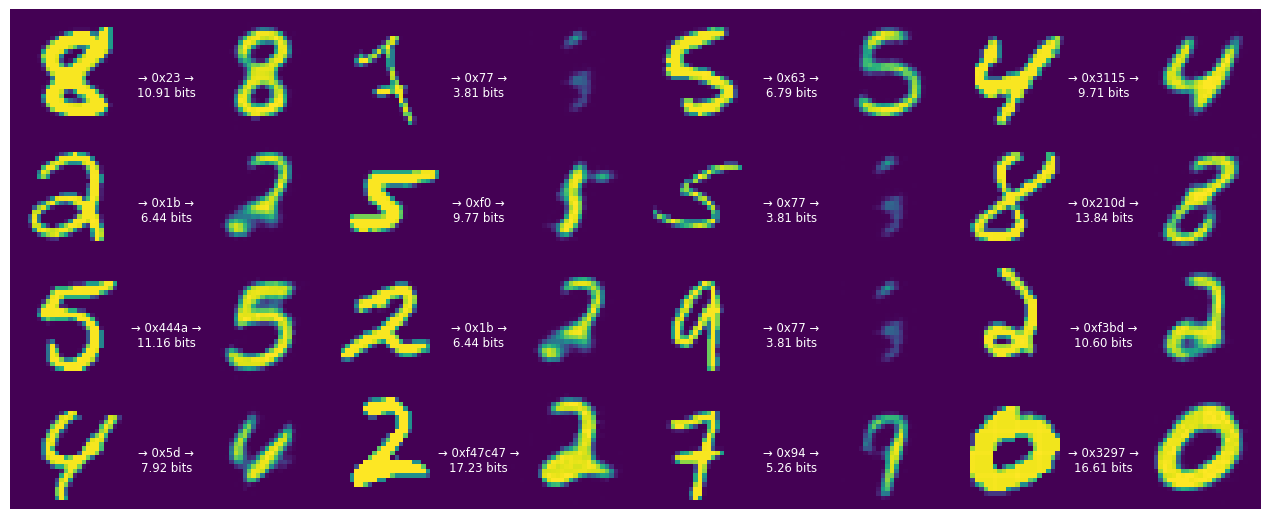

In [41]:
train_and_visualize_model(lmbda=300)


The strings begin to get much shorter now, on the order of one byte per digit. However, this comes at a cost. More digits are becoming unrecognizable.

This demonstrates that this model is agnostic to human perceptions of error, it just measures the absolute deviation in terms of pixel values. To achieve a better perceived image quality, we would need to replace the pixel loss with a perceptual loss.

## Use the decoder as a generative model.

If we feed the decoder random bits, this will effectively sample from the distribution that the model learned to represent digits.

First, re-instantiate the compressor/decompressor without a sanity check that would detect if the input string isn't completely decoded.

In [42]:
compressor, decompressor = make_mnist_codec(trainer, decode_sanity_check=False)


Now, feed long enough random strings into the decompressor so that it can decode/sample digits from them.

2023-12-21 15:48:18.911201: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #0 final status was an error
2023-12-21 15:48:18.911295: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #1 final status was an error
2023-12-21 15:48:18.911312: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #2 final status was an error
2023-12-21 15:48:18.911325: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #3 final status was an error
2023-12-21 15:48:18.911339: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #4 final status was an error
2023-12-21 15:48:18.911351: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #5 final status was an error
2023-12-21 15:48:18.911363: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #6 final status was an error
2023-12-21 15:48:18.911375: I tensorflow_compression/cc/kernel

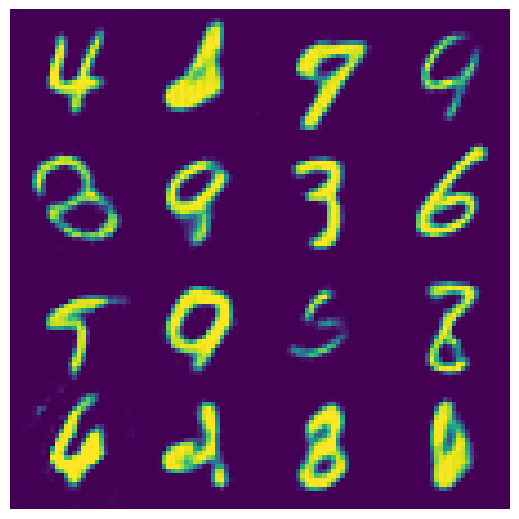

In [44]:
import os

strings = tf.constant([os.urandom(8) for _ in range(16)])
samples = decompressor(strings)

fig, axes = plt.subplots(4, 4, sharex=True, sharey=True, figsize=(5, 5))
axes = axes.ravel()
for i in range(len(axes)):
  axes[i].imshow(tf.squeeze(samples[i]))
  axes[i].axis("off")
plt.subplots_adjust(wspace=0, hspace=0, left=0, right=1, bottom=0, top=1)
